<a href="https://colab.research.google.com/github/greymatter1005/indian-liver-patient-ml/blob/main/Indian_Liver_Patient_ML_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏥 Indian Liver Patient Dataset — ML Classification

**Dataset:** Indian Liver Patient Dataset (583 patients, Andhra Pradesh)  
**Task:** Binary classification — predict whether a patient has liver disease  
**Target column:** `Dataset` (1 = liver patient, 2 = not a liver patient)  

**Algorithms compared:**
- Decision Tree
- Random Forest
- K-Nearest Neighbors (KNN)
- Naive Bayes
- Support Vector Machine (SVM) ← best performer


## Step 1: Install & Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print('All libraries imported successfully!')

All libraries imported successfully!


## Step 2: Load the Dataset

Upload `indian_liver_patient.csv` when prompted.

In [ ]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('indian_liver_patient.csv')
print(f'Dataset shape: {df.shape}')
df.head()

Saving indian_liver_patient.csv to indian_liver_patient (3).csv
Dataset shape: (583, 11)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [ ]:
df.tail()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
578,60,Male,0.5,0.1,500,20,34,5.9,1.6,0.37,2
579,40,Male,0.6,0.1,98,35,31,6.0,3.2,1.10,1
580,52,Male,0.8,0.2,245,48,49,6.4,3.2,1.00,1
581,31,Male,1.3,0.5,184,29,32,6.8,3.4,1.00,1
582,38,Male,1.0,0.3,216,21,24,7.3,4.4,1.50,2


## Step 3: Exploratory Data Analysis (EDA)

In [ ]:
print('=== Dataset Info ===')
df.info()
print('\n=== Basic Statistics ===')
df.describe()

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB

=== Basic Statistics ===


,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


In [ ]:
print('=== Missing Values ===')
print(df.isnull().sum())

print('\n=== Target Distribution ===')
print(df['Dataset'].value_counts())
print(f'\nClass 1 (Liver Patient): {(df["Dataset"]==1).sum()} ({(df["Dataset"]==1).mean()*100:.1f}%)')
print(f'Class 2 (Not Patient):   {(df["Dataset"]==2).sum()} ({(df["Dataset"]==2).mean()*100:.1f}%)')

=== Missing Values ===
Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Dataset                       0
dtype: int64

=== Target Distribution ===
Dataset
1    416
2    167
Name: count, dtype: int64

Class 1 (Liver Patient): 416 (71.4%)
Class 2 (Not Patient):   167 (28.6%)


/tmp/ipykernel_493/3517440297.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Dataset', data=df, ax=axes[0], palette='Set2')
/tmp/ipykernel_493/3517440297.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Liver Patient', 'Not a Patient'])


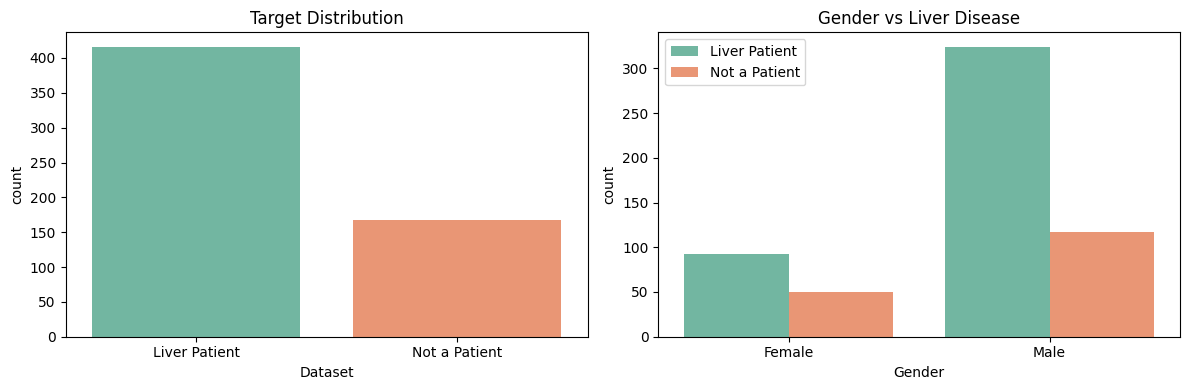

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Target distribution
sns.countplot(x='Dataset', data=df, ax=axes[0], palette='Set2')
axes[0].set_title('Target Distribution')
axes[0].set_xticklabels(['Liver Patient', 'Not a Patient'])

# Gender distribution
sns.countplot(x='Gender', hue='Dataset', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Gender vs Liver Disease')
axes[1].legend(['Liver Patient', 'Not a Patient'])

plt.tight_layout()
plt.show()

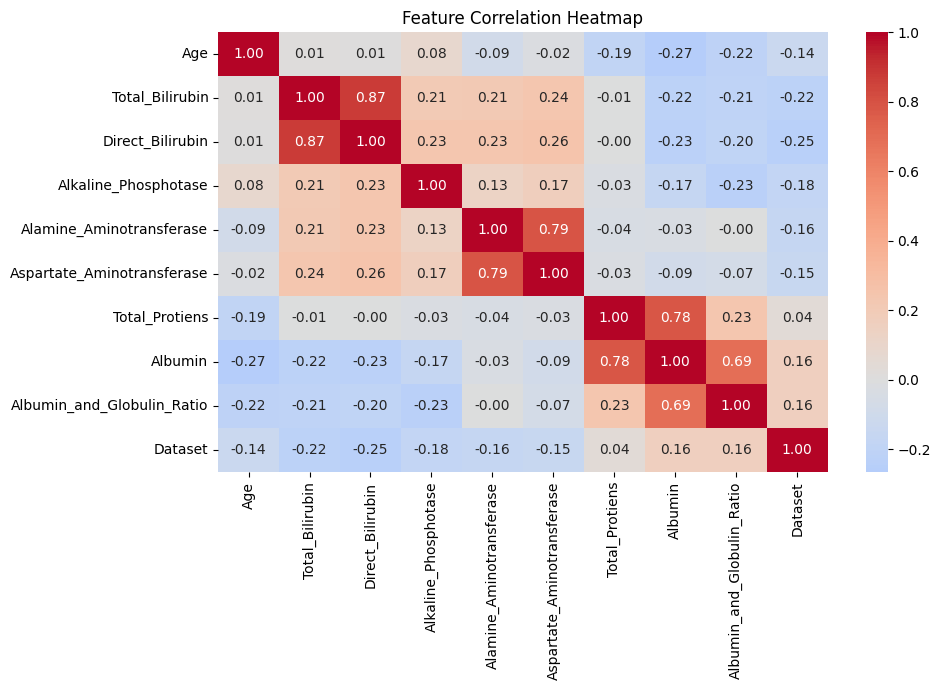

In [ ]:
# Correlation heatmap
plt.figure(figsize=(10, 7))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## Step 4: Data Preprocessing

1. Encode `Gender` (Male=1, Female=0)
2. Handle 4 missing values in `Albumin_and_Globulin_Ratio` → fill with mean
3. Split into features (X) and target (y)
4. Train-test split (80% train, 20% test)
5. Scale features with StandardScaler

In [ ]:
# 1. Encode Gender
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])  # Male=1, Female=0
print('Gender encoded. Unique values:', df['Gender'].unique())

# 2. Handle missing values
df.fillna(df.mean(numeric_only=True), inplace=True)
print(f'Missing values after imputation: {df.isnull().sum().sum()}')

# 3. Separate features and target
X = df.drop('Dataset', axis=1)
y = df['Dataset']
print(f'\nFeatures shape: {X.shape}')
print(f'Target shape: {y.shape}')
print(f'Features: {X.columns.tolist()}')

In [ ]:
# 4. Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f'Training set: {X_train.shape[0]} samples')
print(f'Test set:     {X_test.shape[0]} samples')

# 5. Feature scaling
# IMPORTANT: fit on training data only, then transform both
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit + transform
X_test_scaled  = scaler.transform(X_test)         # transform only (no fit!)
print('\nFeature scaling complete.')
print(f'Train mean (approx 0): {X_train_scaled.mean():.4f}')
print(f'Train std  (approx 1): {X_train_scaled.std():.4f}')

## Step 5: Train and Evaluate All Models

In [ ]:
# Define all models
models = {
    'Decision Tree':    DecisionTreeClassifier(random_state=42),
    'Random Forest':    RandomForestClassifier(n_estimators=100, random_state=42),
    'KNN':              KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes':      GaussianNB(),
    'SVM (RBF kernel)': SVC(kernel='rbf', random_state=42),
}

results = []

print('Training and evaluating models...\n')
print(f'{"Algorithm":<25} {"Accuracy":>10}')
print('-' * 37)

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results.append({'Algorithm': name, 'Accuracy': acc})
    print(f'{name:<25} {acc*100:>9.2f}%')

results_df = results_df = pd.DataFrame(results).sort_values('Accuracy', ascending=False)
print('\n=== Best Model ===')
print(results_df.iloc[0].to_string())

## Step 6: Visualise Results

In [ ]:
plt.figure(figsize=(10, 5))
bars = plt.barh(
    results_df['Algorithm'],
    results_df['Accuracy'] * 100,
    color=['#2196F3' if i == 0 else '#90CAF9' for i in range(len(results_df))]
)
for bar, acc in zip(bars, results_df['Accuracy']):
    plt.text(bar.get_width() - 0.5, bar.get_y() + bar.get_height()/2,
             f'{acc*100:.2f}%', va='center', ha='right', color='white', fontweight='bold')
plt.xlabel('Accuracy (%)')
plt.title('Model Accuracy Comparison — Indian Liver Patient Dataset')
plt.xlim(40, 90)
plt.tight_layout()
plt.show()

## Step 7: Detailed Report for Best Model (SVM)

In [ ]:
# Detailed evaluation of the best model
best_model = SVC(kernel='rbf', random_state=42)
best_model.fit(X_train_scaled, y_train)
y_pred_best = best_model.predict(X_test_scaled)
best_acc = accuracy_score(y_test, y_pred_best)

print(f'=== Best Model: SVM with RBF Kernel ===')
print(f'Accuracy: {best_acc*100:.2f}%\n')
print('Classification Report:')
print(classification_report(y_test, y_pred_best,
                             target_names=['Liver Patient', 'Not a Patient']))

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Liver Patient', 'Not a Patient'],
            yticklabels=['Liver Patient', 'Not a Patient'])
plt.title(f'Confusion Matrix — SVM (Accuracy: {best_acc*100:.2f}%)')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

## Summary

| Algorithm | Accuracy |
|-----------|----------|
| **SVM (RBF kernel)** | **74.36%** |
| Random Forest | 72.65% |
| Decision Tree | 71.79% |
| KNN | 66.67% |
| Naive Bayes | 51.28% |

**Best model: SVM with RBF kernel — 74.36% accuracy**

SVM performed best because:
1. It finds the optimal separating hyperplane between liver patients and non-patients
2. The RBF kernel handles non-linear boundaries in the feature space
3. It is robust to high-dimensional data (10 features)
4. Feature scaling (StandardScaler) is applied, which SVM requires for optimal performance
